# EDA Course Project — Video Presentation

Name: Nidhi Karva  
Registration Number: 23BDS0031  
Project: Exploratory Data Analysis Using Python

Video Presentation: https://drive.google.com/file/d/1cwKxCAFdjbe1wHAeYrAKXCvQmI06Cjxm/view?usp=sharing

The video provides a walkthrough of the project, explaining the assessments, methodologies, visualizations, and findings.

In [13]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import skew, kurtosis, zscore
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import pdist
from sklearn.preprocessing import StandardScaler, MinMaxScaler, MinMaxScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

DATA_URL = "https://raw.githubusercontent.com/salemprakash/EDA/main/Data/SuicideChina.csv"
data = pd.read_csv(DATA_URL)

print("Shape:", data.shape)
display(data.head())
display(data.info())
display(data.describe(include="all").T)
print("Columns:", data.columns.tolist())

Shape: (2571, 12)


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
0,1,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison
1,2,2,no,yes,no,2009,3,male,83,primary,farming,Hanging
2,3,3,no,yes,no,2010,2,male,60,primary,farming,Hanging
3,4,4,no,yes,no,2011,1,male,73,primary,farming,Hanging
4,5,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide


<class 'pandas.DataFrame'>
RangeIndex: 2571 entries, 0 to 2570
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   rownames      2571 non-null   int64
 1   Person_ID     2571 non-null   int64
 2   Hospitalised  2571 non-null   str  
 3   Died          2571 non-null   str  
 4   Urban         2571 non-null   str  
 5   Year          2571 non-null   int64
 6   Month         2571 non-null   int64
 7   Sex           2571 non-null   str  
 8   Age           2571 non-null   int64
 9   Education     2571 non-null   str  
 10  Occupation    2571 non-null   str  
 11  method        2571 non-null   str  
dtypes: int64(5), str(7)
memory usage: 241.2 KB


None

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Person_ID,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Hospitalised,2571,2,yes,1553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Died,2571,2,no,1315,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Urban,2571,3,no,2213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2571.0,NaN,NaN,NaN,2010.045508,0.791412,2009.0,2009.0,2010.0,2011.0,2011.0
Month,2571.0,NaN,NaN,NaN,6.298327,3.202515,1.0,4.0,6.0,9.0,12.0
Sex,2571,2,female,1328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2571.0,NaN,NaN,NaN,52.630883,19.783878,12.0,37.0,53.0,69.0,100.0
Education,2571,5,Secondary,1280,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Columns: ['rownames', 'Person_ID', 'Hospitalised', 'Died', 'Urban', 'Year', 'Month', 'Sex', 'Age', 'Education', 'Occupation', 'method']


In [14]:
dataframe1 = pd.DataFrame({
    "ProductID": range(1, 11),
    "NameofProd": ["Pen", "Book", "Bag", "Pencil", "Bottle", "Ruler", "Eraser", "File", "Marker", "Notebook"],
    "Price": [10, 80, 450, 5, 120, 20, 4, 35, 25, 60]
})

dataframe2 = pd.DataFrame({
    "ProductID": [1, 2, 3, 4, 5, 11, 12, 13, 14, 15],
    "Company_Location": ["Chennai", "Pune", "Delhi", "Mumbai", "Jaipur",
                         "Kochi", "Bengaluru", "Hyderabad", "Surat", "Nagpur"]
})

dataframe3 = pd.DataFrame({
    "ProductID": range(11, 21),
    "NameofProd": ["Stapler", "Glue", "Scissors", "Tape", "Folder", "Calculator", "Clip", "Paint", "Brush", "Pouch"],
    "Price": [90, 30, 70, 25, 40, 350, 8, 55, 45, 100]
})

print("dataframe1"); display(dataframe1)
print("dataframe2"); display(dataframe2)
print("dataframe3"); display(dataframe3)

# 1. Append rows of dataframe1 and dataframe3
appended = pd.concat([dataframe1, dataframe3], ignore_index=True)
display(appended)

# 2. Concatenate applicable data frames column-wise (example: first 10 rows)
concatenated_columns = pd.concat(
    [dataframe1.reset_index(drop=True), dataframe2.iloc[:10].reset_index(drop=True)],
    axis=1
)
display(concatenated_columns)

# 3. Merge dataframe1 and dataframe2 by ProductID
merged = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
display(merged)

# 4. Join types
inner_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="inner")
left_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="left")
right_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="right")
full_outer_join = pd.merge(dataframe1, dataframe2, on="ProductID", how="outer")

print("Inner join"); display(inner_join)
print("Left join"); display(left_join)
print("Right join"); display(right_join)
print("Full outer join"); display(full_outer_join)

dataframe1


,ProductID,NameofProd,Price
0,1,Pen,10
1,2,Book,80
2,3,Bag,450
3,4,Pencil,5
4,5,Bottle,120
5,6,Ruler,20
6,7,Eraser,4
7,8,File,35
8,9,Marker,25
9,10,Notebook,60


dataframe2


,ProductID,Company_Location
0,1,Chennai
1,2,Pune
2,3,Delhi
3,4,Mumbai
4,5,Jaipur
5,11,Kochi
6,12,Bengaluru
7,13,Hyderabad
8,14,Surat
9,15,Nagpur


dataframe3


,ProductID,NameofProd,Price
0,11,Stapler,90
1,12,Glue,30
2,13,Scissors,70
3,14,Tape,25
4,15,Folder,40
5,16,Calculator,350
6,17,Clip,8
7,18,Paint,55
8,19,Brush,45
9,20,Pouch,100


... (7 outputs left out)

Right join


,ProductID,NameofProd,Price,Company_Location
0,1,Pen,10.0,Chennai
1,2,Book,80.0,Pune
2,3,Bag,450.0,Delhi
3,4,Pencil,5.0,Mumbai
4,5,Bottle,120.0,Jaipur
5,11,NaN,NaN,Kochi
6,12,NaN,NaN,Bengaluru
7,13,NaN,NaN,Hyderabad
8,14,NaN,NaN,Surat
9,15,NaN,NaN,Nagpur


Full outer join


,ProductID,NameofProd,Price,Company_Location
0,1,Pen,10.0,Chennai
1,2,Book,80.0,Pune
2,3,Bag,450.0,Delhi
3,4,Pencil,5.0,Mumbai
4,5,Bottle,120.0,Jaipur
5,6,Ruler,20.0,NaN
6,7,Eraser,4.0,NaN
7,8,File,35.0,NaN
8,9,Marker,25.0,NaN
9,10,Notebook,60.0,NaN


In [ ]:
REGISTRATION_LAST4 = 31 
Fname = np.array([31, 12, 18, 25, 31, 42, 56, 63, 77, 89], dtype=float)

# Normalize to [-3, 3] and [-1, 1] using min-max scaling
def normalize_range(x, low, high):
    return low + (x - np.min(x)) * (high - low) / (np.max(x) - np.min(x))

norm_neg3_pos3 = normalize_range(Fname, -3, 3)
norm_neg1_pos1 = normalize_range(Fname, -1, 1)
minmax_0_1 = normalize_range(Fname, 0, 1)

# Z-score normalization
z_score = (Fname - Fname.mean()) / Fname.std(ddof=0)

# Decimal scaling normalization
j = int(np.ceil(np.log10(np.max(np.abs(Fname)) + 1)))
decimal_scaling = Fname / (10 ** j)

print("Original:", Fname)
print("[-3, 3]:", norm_neg3_pos3)
print("[-1, 1]:", norm_neg1_pos1)
print("[0, 1]:", minmax_0_1)
print("Z-score:", z_score)
print("Decimal scaling:", decimal_scaling)

Original: [31. 12. 18. 25. 31. 42. 56. 63. 77. 89.]
[-3, 3]: [-1.51948052 -3.         -2.53246753 -1.98701299 -1.51948052 -0.66233766
  0.42857143  0.97402597  2.06493506  3.        ]
[-1, 1]: [-0.50649351 -1.         -0.84415584 -0.66233766 -0.50649351 -0.22077922
  0.14285714  0.32467532  0.68831169  1.        ]
[0, 1]: [0.24675325 0.         0.07792208 0.16883117 0.24675325 0.38961039
 0.57142857 0.66233766 0.84415584 1.        ]
Z-score: [-0.54612508 -1.32048155 -1.07594793 -0.7906587  -0.54612508 -0.09781345
  0.472765    0.75805422  1.32863267  1.81769991]
Decimal scaling: [0.31 0.12 0.18 0.25 0.31 0.42 0.56 0.63 0.77 0.89]


In [ ]:
df2 = data.copy()

# 1–7: first/last 10 rows, shape, names, types, summary
display(df2.head(10))
display(df2.tail(10))
print("Rows, columns:", df2.shape)
print("Column names:", df2.columns.tolist())
print(df2.dtypes)
display(df2.describe(include="all").T)

# 8–11: missing values and rows containing missing values
print("Missing values per column:")
print(df2.isna().sum())
print("Total missing values:", int(df2.isna().sum().sum()))
display(df2[df2.isna().any(axis=1)].head(10))

# 12: remove rows with any missing value
df2_dropped = df2.dropna()
print("Shape after dropping missing rows:", df2_dropped.shape)

# 13–15: numeric mean/median and categorical mode imputation
numeric_cols = df2.select_dtypes(include=np.number).columns.tolist()
categorical_cols = df2.select_dtypes(exclude=np.number).columns.tolist()
df2_imputed = df2.copy()

if numeric_cols:
    col_mean = numeric_cols[0]
    df2_imputed[col_mean] = df2_imputed[col_mean].fillna(df2_imputed[col_mean].mean())
if len(numeric_cols) > 1:
    col_median = numeric_cols[1]
    df2_imputed[col_median] = df2_imputed[col_median].fillna(df2_imputed[col_median].median())
if categorical_cols:
    col_mode = categorical_cols[0]
    modes = df2_imputed[col_mode].mode(dropna=True)
    if not modes.empty:
        df2_imputed[col_mode] = df2_imputed[col_mode].fillna(modes.iloc[0])

# 16–17: forward fill and backward fill
df2_forward = df2.ffill()
df2_backward = df2.bfill()

# 18: replace remaining missing values with 0 / "Unknown"
df2_constant = df2.copy()
for col in df2_constant.columns:
    if pd.api.types.is_numeric_dtype(df2_constant[col]):
        df2_constant[col] = df2_constant[col].fillna(0)
    else:
        df2_constant[col] = df2_constant[col].fillna("Unknown")

# 19: remove duplicates
df2_no_duplicates = df2.drop_duplicates()
print("Duplicate rows removed:", len(df2) - len(df2_no_duplicates))

# 20: convert appropriate text columns to category
for col in categorical_cols:
    df2_imputed[col] = df2_imputed[col].astype("category")

# 21: rename one column (example)
df2_renamed = df2.rename(columns={"method": "Method"})
print("Renamed columns:", df2_renamed.columns.tolist())

# 22: derived column example
if "Age" in df2.columns:
    df2["Age_Group"] = pd.cut(
        df2["Age"], bins=[0, 18, 30, 45, 60, 75, 101],
        labels=["Below 18", "18-30", "31-45", "46-60", "61-75", "76-100"],
        include_lowest=True
    )

# 23–28: summary and numeric statistics
display(df2.describe(include="all").T)
if numeric_cols:
    c = "Age" if "Age" in numeric_cols else numeric_cols[0]
    x = df2[c].dropna()
    print(f"{c}: min={x.min()}, max={x.max()}, range={x.max()-x.min()}, "
          f"variance={x.var()}, std={x.std()}, IQR={x.quantile(.75)-x.quantile(.25)}")

,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
0,1,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison
1,2,2,no,yes,no,2009,3,male,83,primary,farming,Hanging
2,3,3,no,yes,no,2010,2,male,60,primary,farming,Hanging
3,4,4,no,yes,no,2011,1,male,73,primary,farming,Hanging
4,5,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide
5,6,6,no,yes,no,2009,11,male,62,iliterate,farming,Pesticide
6,7,7,no,yes,no,2010,1,female,90,iliterate,farming,Pesticide
7,8,8,yes,no,no,2010,10,male,54,Secondary,farming,Pesticide
8,9,9,no,yes,no,2010,7,male,66,primary,farming,Hanging
9,10,10,yes,no,no,2011,1,female,30,Secondary,others/unknown,Poison unspec


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
2561,2562,2562,yes,no,unknown,2010,3,male,31,unknown,others/unknown,Other poison
2562,2563,2563,yes,no,unknown,2011,9,male,50,Secondary,farming,Pesticide
2563,2564,2564,yes,no,unknown,2010,11,female,43,primary,farming,Pesticide
2564,2565,2565,yes,no,unknown,2011,8,female,30,Secondary,household,Pesticide
2565,2566,2566,yes,no,unknown,2011,6,male,23,Secondary,professional,Pesticide
2566,2567,2567,yes,no,unknown,2010,7,male,28,primary,household,Pesticide
2567,2568,2568,yes,no,unknown,2011,6,male,35,Secondary,farming,Pesticide
2568,2569,2569,yes,no,unknown,2011,9,female,22,Secondary,unemployed,Other poison
2569,2570,2570,yes,no,unknown,2010,8,female,50,Secondary,farming,Pesticide
2570,2571,2571,yes,no,unknown,2010,7,female,44,primary,farming,Pesticide


Rows, columns: (2571, 12)
Column names: ['rownames', 'Person_ID', 'Hospitalised', 'Died', 'Urban', 'Year', 'Month', 'Sex', 'Age', 'Education', 'Occupation', 'method']
rownames        int64
Person_ID       int64
Hospitalised      str
Died              str
Urban             str
Year            int64
Month           int64
Sex               str
Age             int64
Education         str
Occupation        str
method            str
dtype: object


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Person_ID,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Hospitalised,2571,2,yes,1553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Died,2571,2,no,1315,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Urban,2571,3,no,2213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2571.0,NaN,NaN,NaN,2010.045508,0.791412,2009.0,2009.0,2010.0,2011.0,2011.0
Month,2571.0,NaN,NaN,NaN,6.298327,3.202515,1.0,4.0,6.0,9.0,12.0
Sex,2571,2,female,1328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2571.0,NaN,NaN,NaN,52.630883,19.783878,12.0,37.0,53.0,69.0,100.0
Education,2571,5,Secondary,1280,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing values per column:
rownames        0
Person_ID       0
Hospitalised    0
Died            0
Urban           0
Year            0
Month           0
Sex             0
Age             0
Education       0
Occupation      0
method          0
dtype: int64
Total missing values: 0


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method


Shape after dropping missing rows: (2571, 12)
Duplicate rows removed: 0
Renamed columns: ['rownames', 'Person_ID', 'Hospitalised', 'Died', 'Urban', 'Year', 'Month', 'Sex', 'Age', 'Education', 'Occupation', 'Method']


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
rownames,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Person_ID,2571.0,NaN,NaN,NaN,1286.0,742.328095,1.0,643.5,1286.0,1928.5,2571.0
Hospitalised,2571,2,yes,1553,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Died,2571,2,no,1315,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Urban,2571,3,no,2213,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,2571.0,NaN,NaN,NaN,2010.045508,0.791412,2009.0,2009.0,2010.0,2011.0,2011.0
Month,2571.0,NaN,NaN,NaN,6.298327,3.202515,1.0,4.0,6.0,9.0,12.0
Sex,2571,2,female,1328,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,2571.0,NaN,NaN,NaN,52.630883,19.783878,12.0,37.0,53.0,69.0,100.0
Education,2571,5,Secondary,1280,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Age: min=12, max=100, range=88, variance=391.40183186605464, std=19.78387807953877, IQR=32.0


First six rows


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
0,1,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison
1,2,2,no,yes,no,2009,3,male,83,primary,farming,Hanging
2,3,3,no,yes,no,2010,2,male,60,primary,farming,Hanging
3,4,4,no,yes,no,2011,1,male,73,primary,farming,Hanging
4,5,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide
5,6,6,no,yes,no,2009,11,male,62,iliterate,farming,Pesticide


Last six rows


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
2565,2566,2566,yes,no,unknown,2011,6,male,23,Secondary,professional,Pesticide
2566,2567,2567,yes,no,unknown,2010,7,male,28,primary,household,Pesticide
2567,2568,2568,yes,no,unknown,2011,6,male,35,Secondary,farming,Pesticide
2568,2569,2569,yes,no,unknown,2011,9,female,22,Secondary,unemployed,Other poison
2569,2570,2570,yes,no,unknown,2010,8,female,50,Secondary,farming,Pesticide
2570,2571,2571,yes,no,unknown,2010,7,female,44,primary,farming,Pesticide


Total missing: 0


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method


Duplicate rows: 0
Sex uppercase example: <StringArray>
['FEMALE', 'MALE']
Length: 2, dtype: str


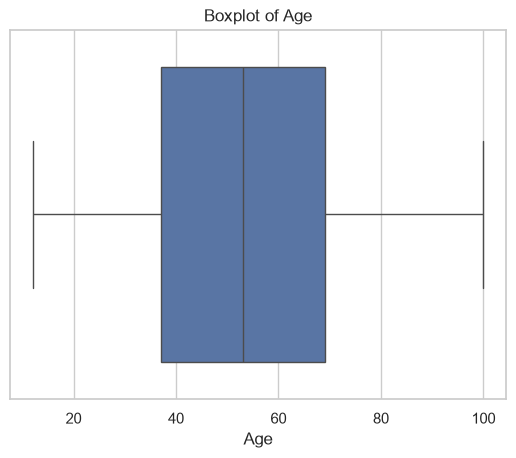

IQR outlier rows: 0


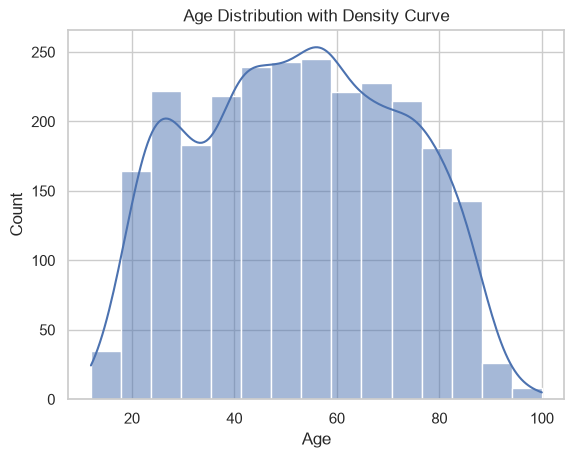

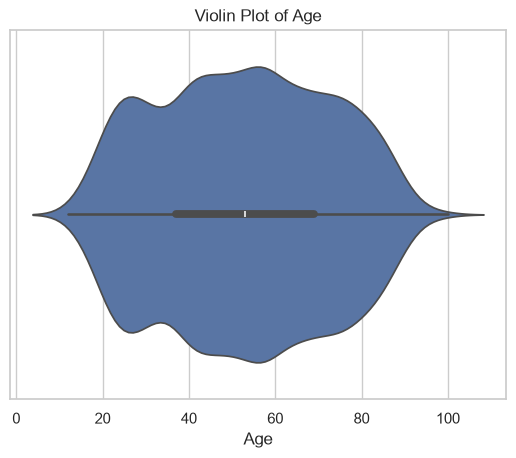

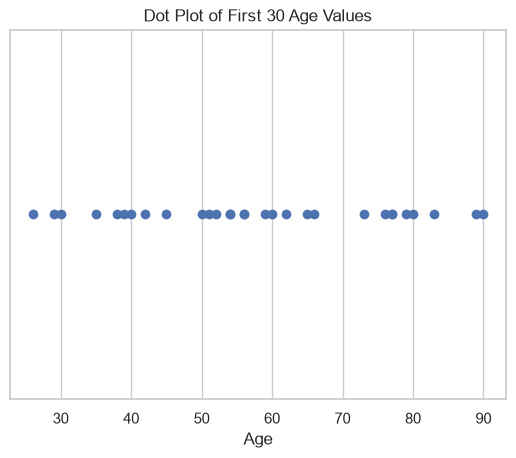

Frequency


,Frequency
Sex,
female,1328
male,1243


Proportion


,Proportion
Sex,
female,0.516531
male,0.483469


Percentage


,Percentage
Sex,
female,51.653053
male,48.346947


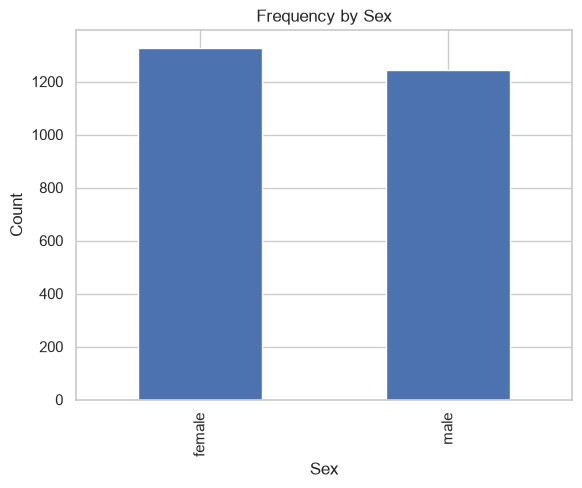

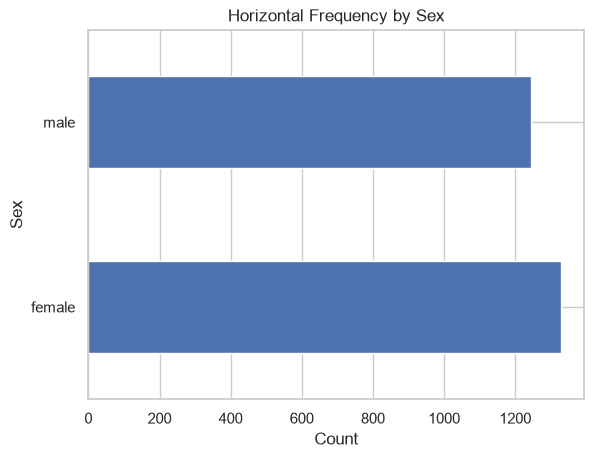

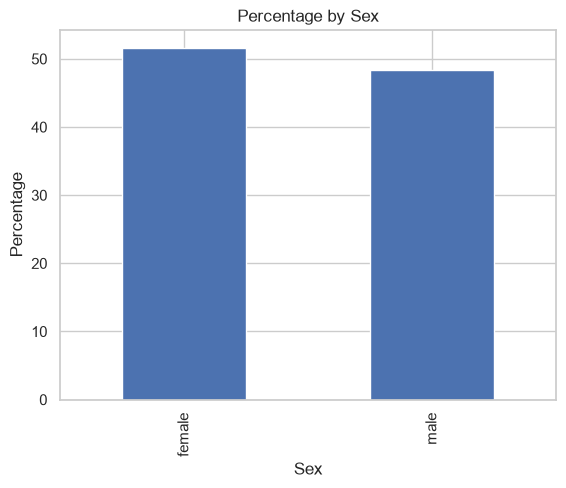

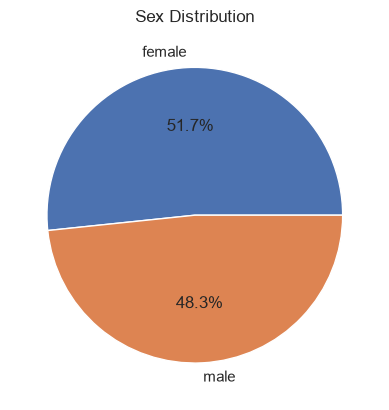

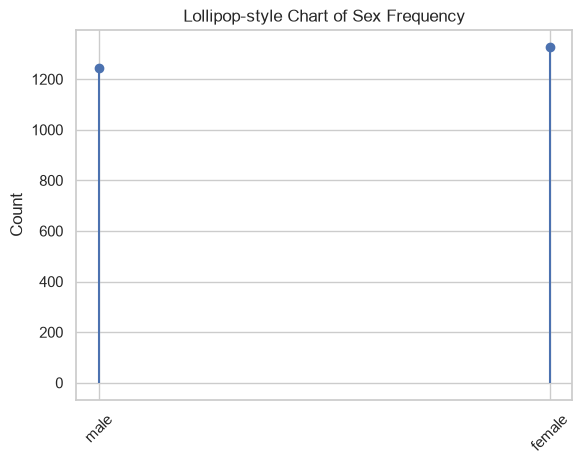

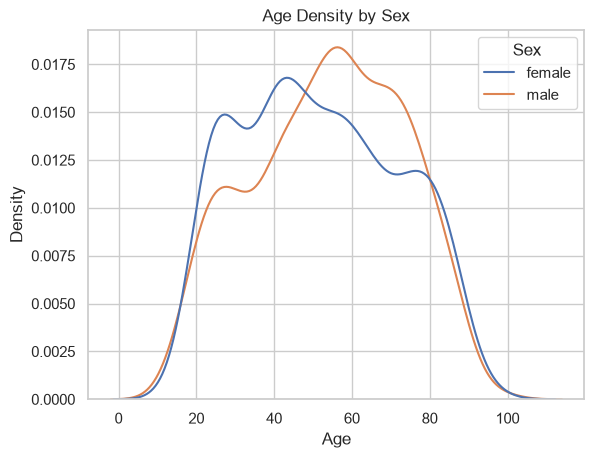

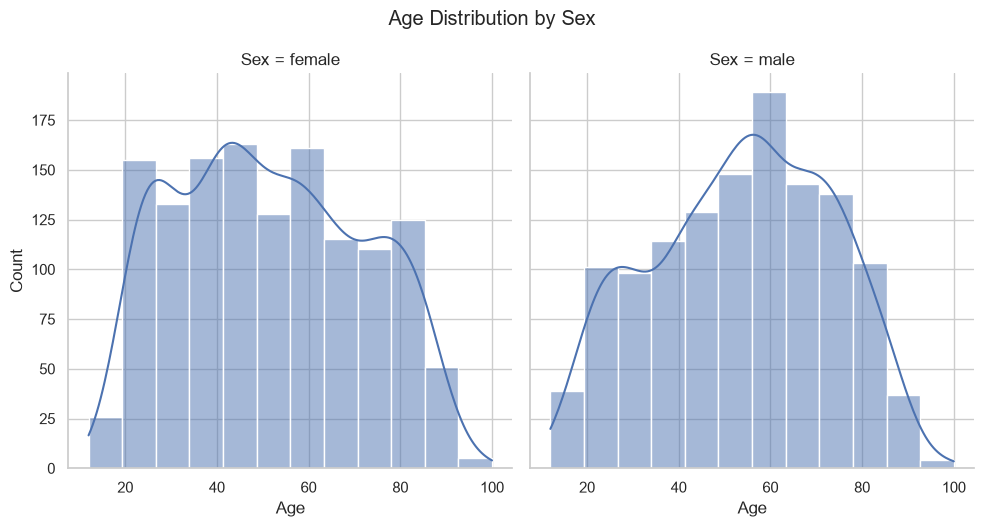

In [ ]:
df3 = data.copy()
print("First six rows"); display(df3.head(6))
print("Last six rows"); display(df3.tail(6))
print("Total missing:", int(df3.isna().sum().sum()))
display(df3[df3.isna().any(axis=1)].head(10))

# Remove columns with >70% missing values
missing_pct = df3.isna().mean() * 100
df3 = df3.loc[:, missing_pct <= 70]

# Fill numeric missing values with mean/median (demonstrations on separate copies)
df3_mean = df3.copy()
for c in df3_mean.select_dtypes(include=np.number).columns:
    df3_mean[c] = df3_mean[c].fillna(df3_mean[c].mean())

df3_median = df3.copy()
for c in df3_median.select_dtypes(include=np.number).columns:
    df3_median[c] = df3_median[c].fillna(df3_median[c].median())

# Fill categorical missing values with mode
df3_clean = df3.copy()
for c in df3_clean.select_dtypes(exclude=np.number).columns:
    m = df3_clean[c].mode(dropna=True)
    if not m.empty:
        df3_clean[c] = df3_clean[c].fillna(m.iloc[0])

print("Duplicate rows:", df3_clean.duplicated().sum())
df3_clean = df3_clean.drop_duplicates()

# Convert strings to categorical and demonstrate case conversion
for c in df3_clean.select_dtypes(include="object").columns:
    df3_clean[c] = df3_clean[c].astype("category")
if "Sex" in df3_clean:
    print("Sex uppercase example:", df3_clean["Sex"].astype(str).str.upper().unique())

# Boxplot and IQR outlier detection for Age
if "Age" in df3_clean:
    sns.boxplot(x=df3_clean["Age"])
    plt.title("Boxplot of Age")
    plt.show()

    q1, q3 = df3_clean["Age"].quantile([.25, .75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    outliers = df3_clean[(df3_clean["Age"] < lower) | (df3_clean["Age"] > upper)]
    print("IQR outlier rows:", len(outliers))
    # Optional removal of extreme outliers:
    df3_no_outliers = df3_clean[df3_clean["Age"].between(lower, upper)].copy()

    # Histogram with density curve
    sns.histplot(df3_clean["Age"], kde=True, bins=15)
    plt.title("Age Distribution with Density Curve")
    plt.xlabel("Age")
    plt.show()

    # Violin and dot plots
    sns.violinplot(x=df3_clean["Age"])
    plt.title("Violin Plot of Age")
    plt.show()
    sample_age = df3_clean["Age"].dropna().head(30)
    plt.plot(sample_age, np.zeros(len(sample_age)), "o")
    plt.yticks([])
    plt.title("Dot Plot of First 30 Age Values")
    plt.xlabel("Age")
    plt.show()

# Categorical frequency tables and charts
if "Sex" in df3_clean:
    freq = df3_clean["Sex"].value_counts()
    rel_freq = df3_clean["Sex"].value_counts(normalize=True)
    print("Frequency"); display(freq.to_frame("Frequency"))
    print("Proportion"); display(rel_freq.to_frame("Proportion"))
    print("Percentage"); display((rel_freq * 100).to_frame("Percentage"))

    freq.plot(kind="bar", title="Frequency by Sex", xlabel="Sex", ylabel="Count")
    plt.show()
    freq.plot(kind="barh", title="Horizontal Frequency by Sex", xlabel="Count", ylabel="Sex")
    plt.show()
    (rel_freq * 100).plot(kind="bar", title="Percentage by Sex", ylabel="Percentage")
    plt.show()
    freq.plot(kind="pie", autopct="%1.1f%%", title="Sex Distribution", ylabel="")
    plt.show()

    # Lollipop and dot chart
    order = freq.sort_values()
    plt.stem(order.values, markerfmt="o", basefmt=" ")
    plt.xticks(range(len(order)), order.index.astype(str), rotation=45)
    plt.title("Lollipop-style Chart of Sex Frequency")
    plt.ylabel("Count")
    plt.show()

    sns.kdeplot(data=df3_clean, x="Age", hue="Sex", common_norm=False)
    plt.title("Age Density by Sex")
    plt.show()

    # facet_wrap equivalent: distribution of Age by Sex
    g = sns.displot(data=df3_clean, x="Age", col="Sex", kde=True, bins=12)
    g.fig.suptitle("Age Distribution by Sex", y=1.05)
    plt.show()

Died,no,yes
Sex,,
female,741,587
male,574,669


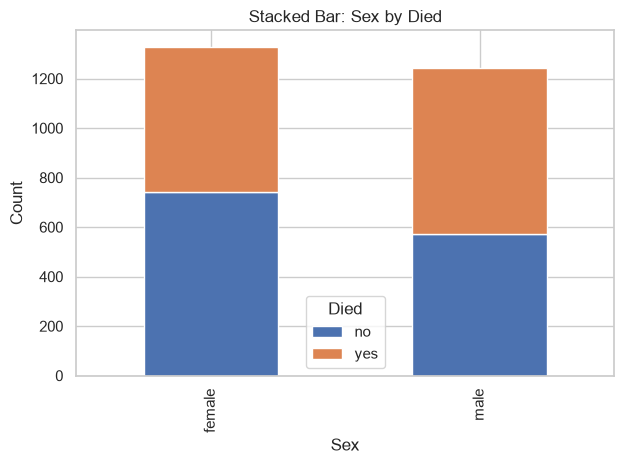

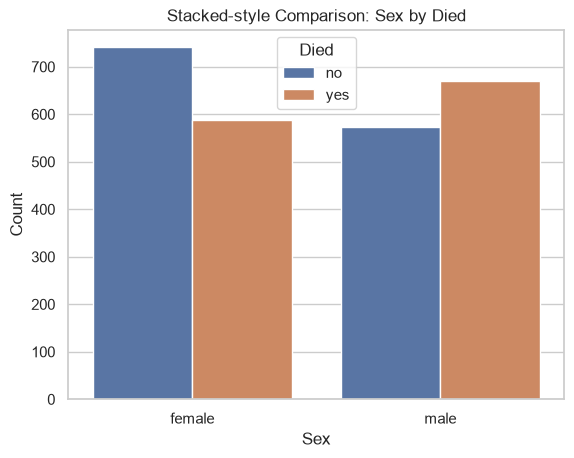

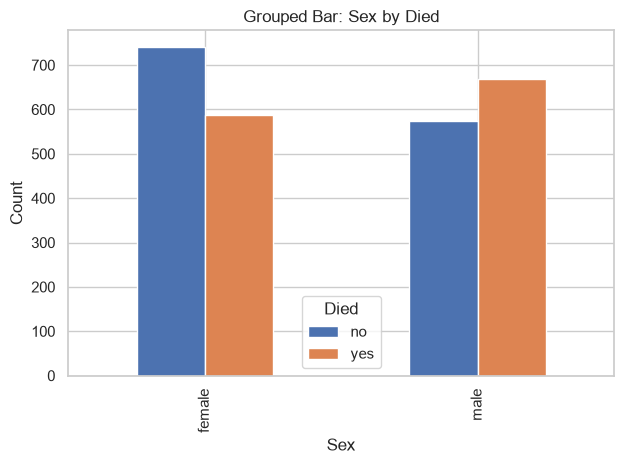

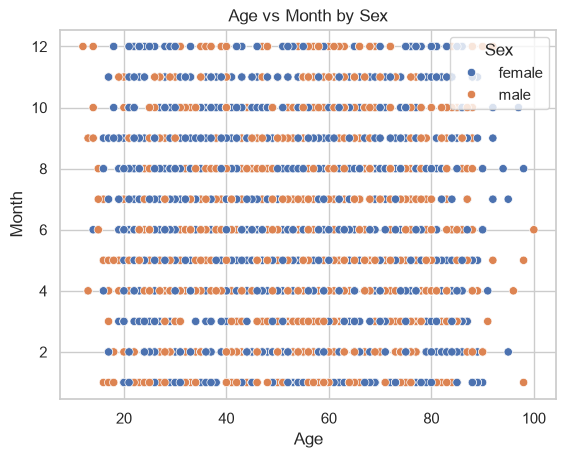

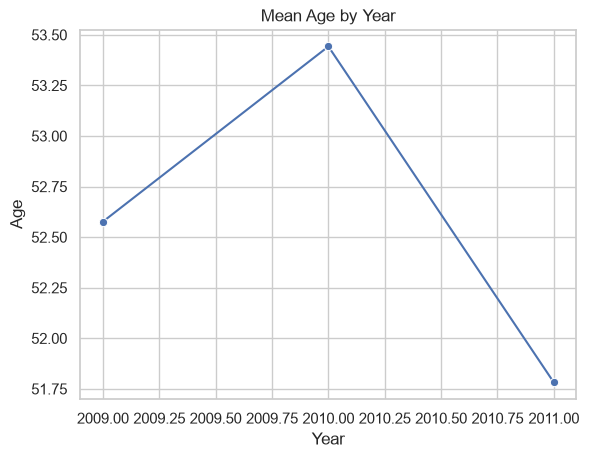

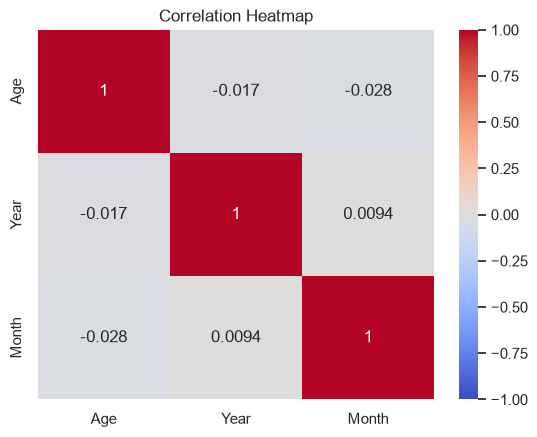

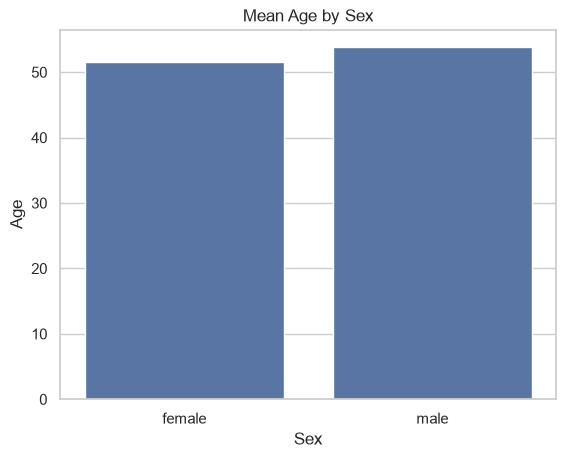

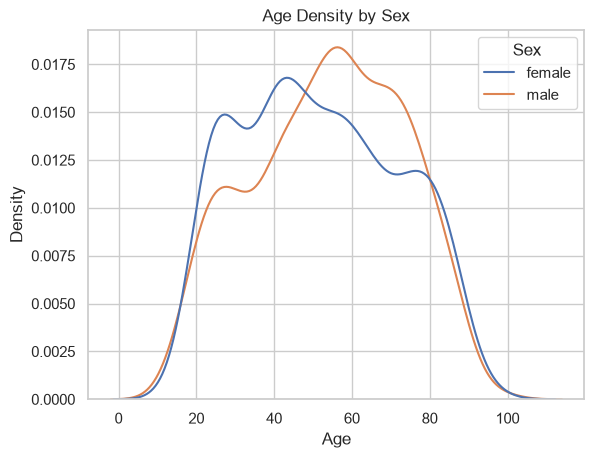

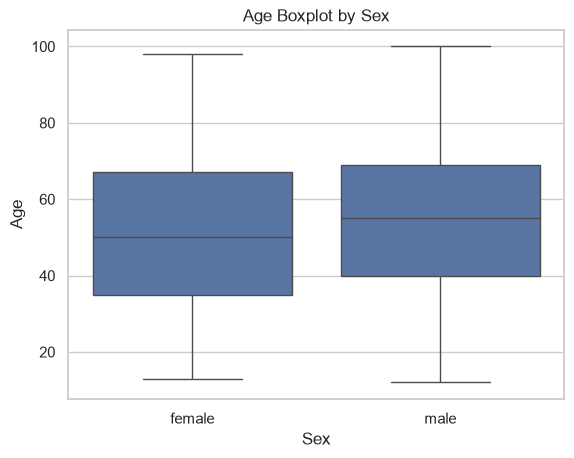

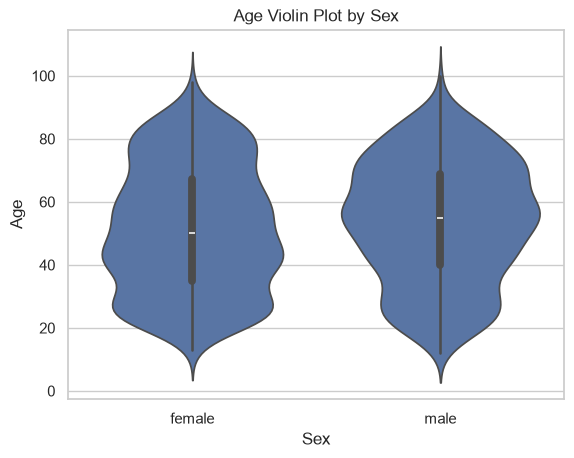

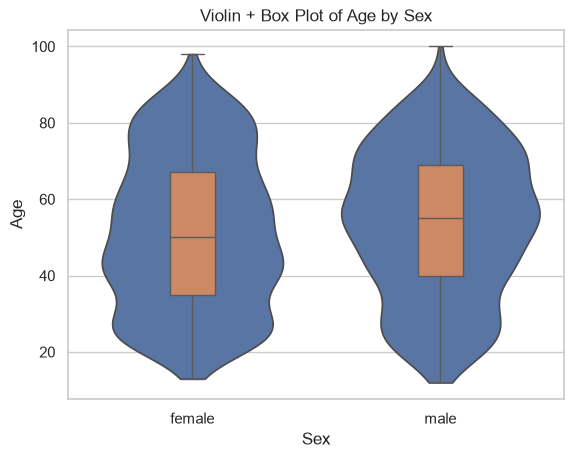

,Age,Year,Month
Age,1.000000,-0.017267,-0.028397
Year,-0.017267,1.000000,0.009380
Month,-0.028397,0.009380,1.000000


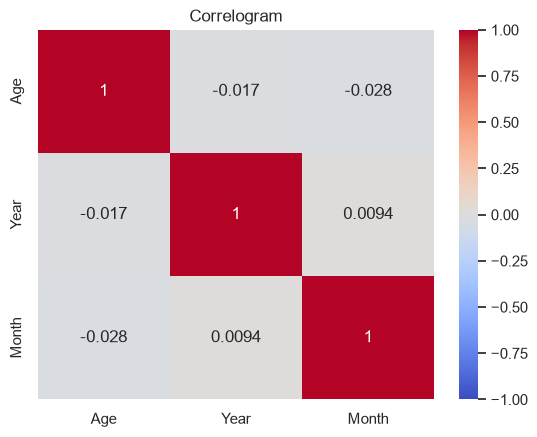

In [ ]:
df4 = data.copy()

# 1–2. Contingency table and stacked bars
ct = pd.crosstab(df4["Sex"], df4["Died"])
display(ct)
ct.plot(kind="bar", stacked=True, title="Stacked Bar: Sex by Died")
plt.xlabel("Sex"); plt.ylabel("Count"); plt.tight_layout(); plt.show()

ct_long = df4.groupby(["Sex", "Died"], observed=False).size().reset_index(name="Count")
sns.barplot(data=ct_long, x="Sex", y="Count", hue="Died")
plt.title("Stacked-style Comparison: Sex by Died")
plt.show()

# 3. Grouped/side-by-side bar plot
ct.plot(kind="bar", stacked=False, title="Grouped Bar: Sex by Died")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

# 4. Scatter plot
sns.scatterplot(data=df4, x="Age", y="Month", hue="Sex")
plt.title("Age vs Month by Sex"); plt.show()

# 5. Line plot of average age by year
year_age = df4.groupby("Year", as_index=False)["Age"].mean()
sns.lineplot(data=year_age, x="Year", y="Age", marker="o")
plt.title("Mean Age by Year"); plt.show()

# 6. Heatmap of numeric relationships
sns.heatmap(df4[["Age", "Year", "Month"]].corr(), annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Heatmap"); plt.show()

# 7. Bar chart comparing mean age by sex
sns.barplot(data=df4, x="Sex", y="Age", errorbar=None)
plt.title("Mean Age by Sex"); plt.show()

# 8–11. Density, box, violin, combined violin and box
sns.kdeplot(data=df4, x="Age", hue="Sex", common_norm=False)
plt.title("Age Density by Sex"); plt.show()

sns.boxplot(data=df4, x="Sex", y="Age")
plt.title("Age Boxplot by Sex"); plt.show()

sns.violinplot(data=df4, x="Sex", y="Age")
plt.title("Age Violin Plot by Sex"); plt.show()

sns.violinplot(data=df4, x="Sex", y="Age", inner=None, cut=0)
sns.boxplot(data=df4, x="Sex", y="Age", width=.18, showfliers=False)
plt.title("Violin + Box Plot of Age by Sex"); plt.show()

# 12. Correlation matrix and correlogram
corr = df4[["Age", "Year", "Month"]].corr()
display(corr)
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlogram"); plt.show()

Numeric columns: ['rownames', 'Person_ID', 'Year', 'Month', 'Age', 'Age_squared']
Categorical columns: ['Hospitalised', 'Died', 'Urban', 'Sex', 'Education', 'Occupation', 'method']


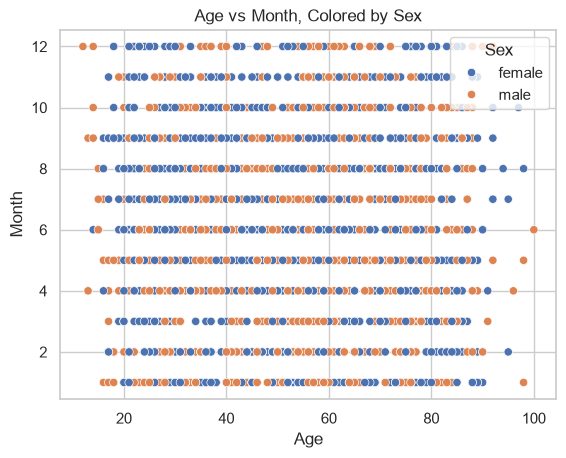

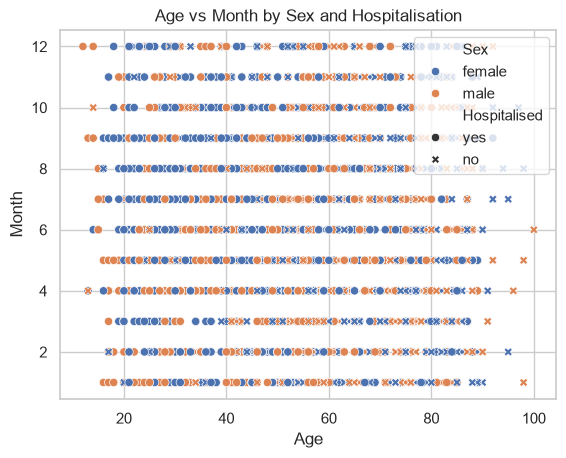

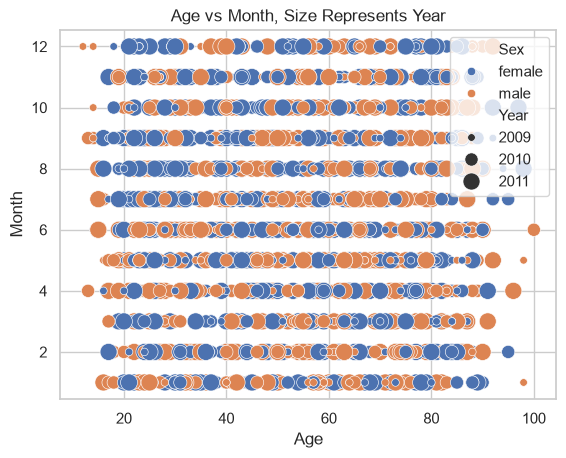

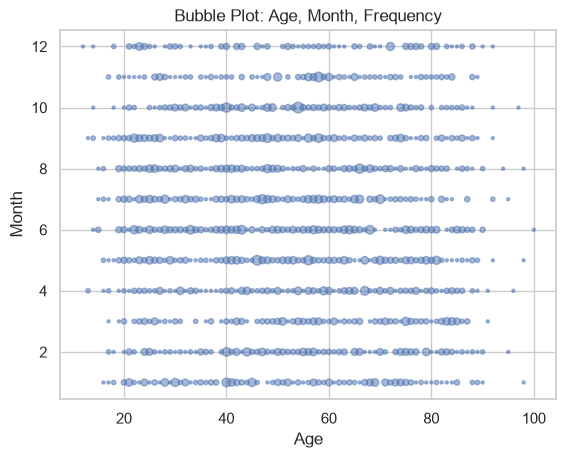

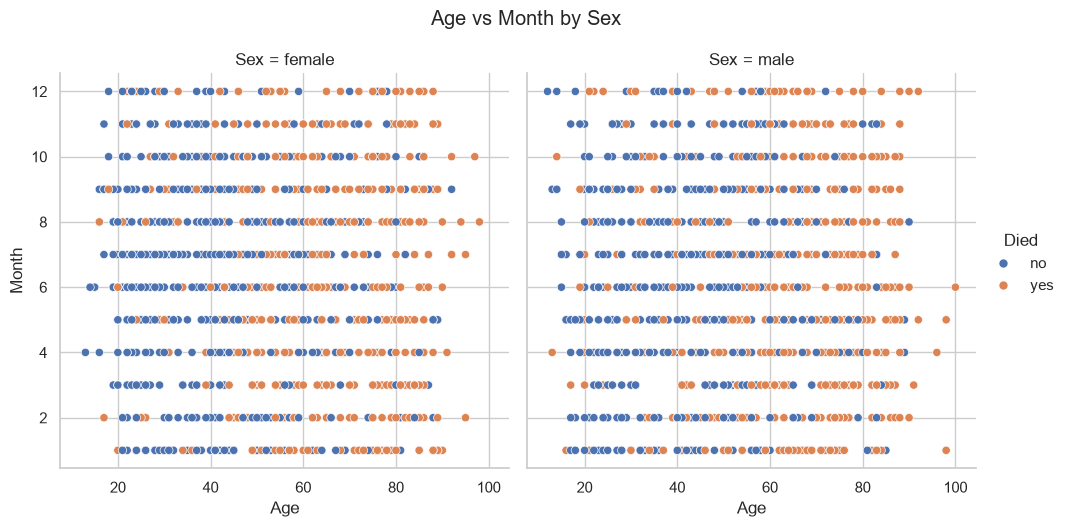

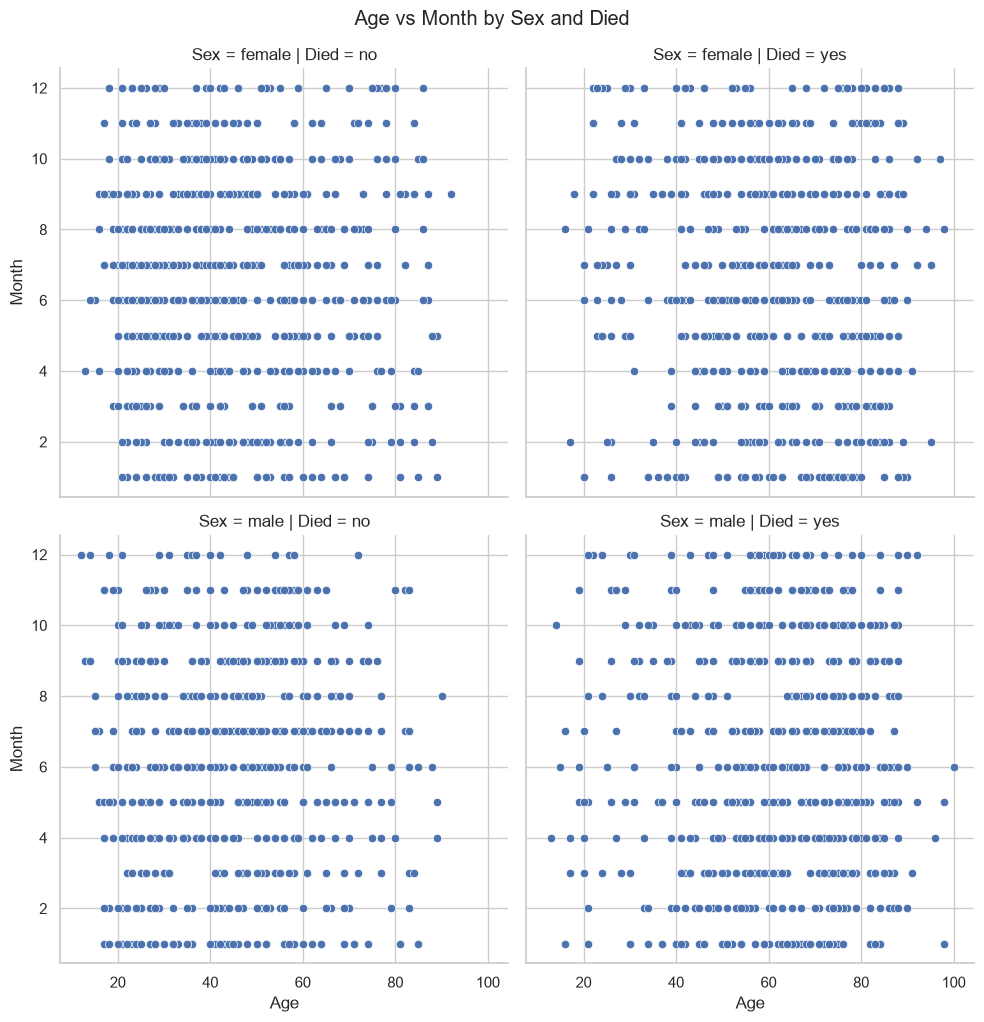

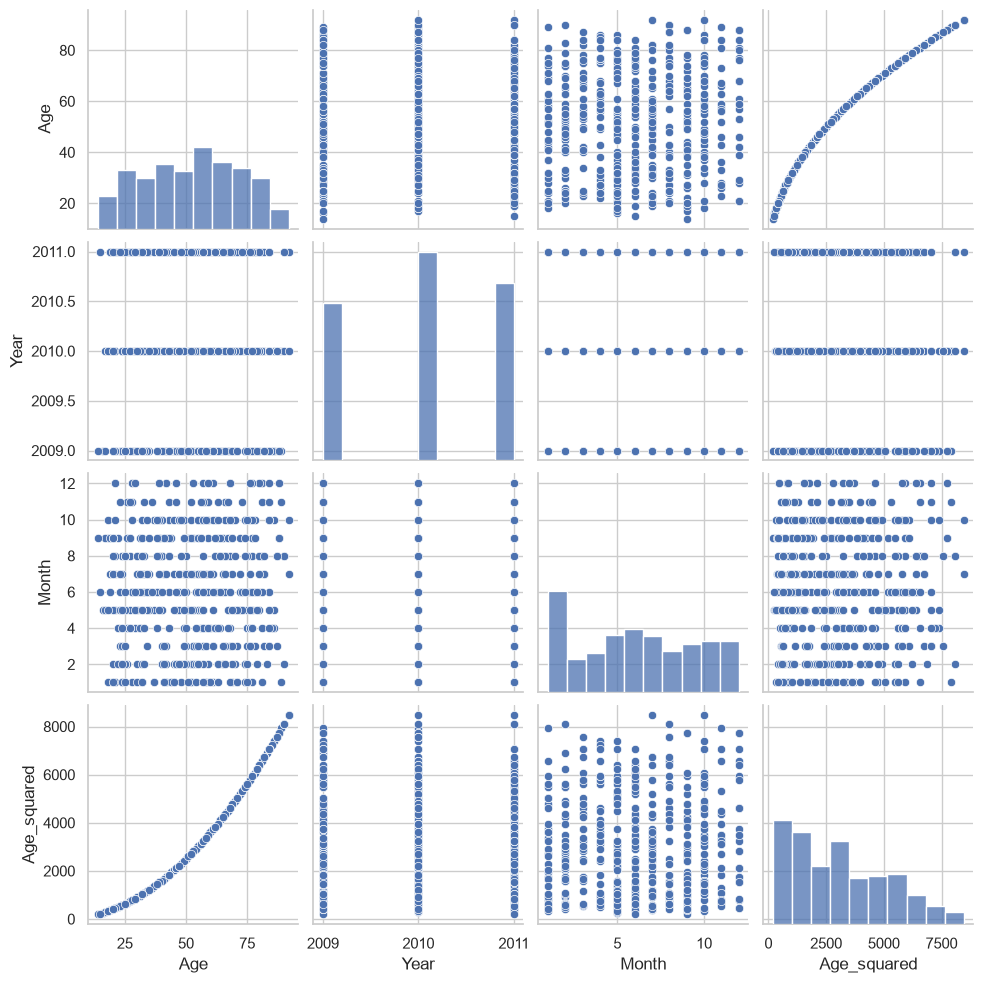

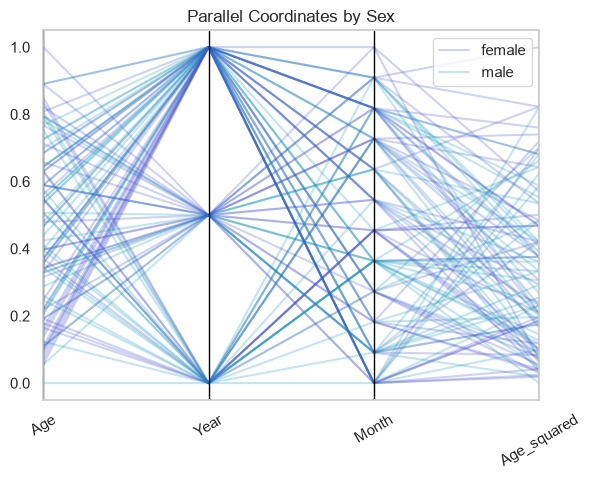

In [ ]:
df5 = data.copy()
df5["Age_squared"] = df5["Age"] ** 2
print("Numeric columns:", df5.select_dtypes(include=np.number).columns.tolist())
print("Categorical columns:", df5.select_dtypes(exclude=np.number).columns.tolist())

# 2. 3 variables: x, y, color
sns.scatterplot(data=df5, x="Age", y="Month", hue="Sex")
plt.title("Age vs Month, Colored by Sex"); plt.show()

# 3. 4 variables: x, y, color, shape
sns.scatterplot(data=df5, x="Age", y="Month", hue="Sex", style="Hospitalised")
plt.title("Age vs Month by Sex and Hospitalisation"); plt.show()

# 4. x, y, color, numerical size
sns.scatterplot(data=df5, x="Age", y="Month", hue="Sex", size="Year", sizes=(30, 150))
plt.title("Age vs Month, Size Represents Year"); plt.show()

# 5. Bubble plot with three numerical variables
bubble = df5.groupby(["Age", "Month"], as_index=False).size().rename(columns={"size":"Frequency"})
plt.scatter(bubble["Age"], bubble["Month"], s=bubble["Frequency"] * 5, alpha=.5)
plt.xlabel("Age"); plt.ylabel("Month"); plt.title("Bubble Plot: Age, Month, Frequency"); plt.show()

# 6. facet_wrap equivalent
g = sns.relplot(data=df5, x="Age", y="Month", col="Sex", hue="Died", kind="scatter")
g.fig.suptitle("Age vs Month by Sex", y=1.05); plt.show()

# 7. facet_grid equivalent
g = sns.relplot(data=df5, x="Age", y="Month", row="Sex", col="Died", kind="scatter")
g.fig.suptitle("Age vs Month by Sex and Died", y=1.02); plt.show()

# 8. Pairs plot (four numeric columns; Age_squared is derived)
sns.pairplot(df5[["Age", "Year", "Month", "Age_squared"]].sample(min(500, len(df5)), random_state=RANDOM_STATE))
plt.show()

# 9. Parallel coordinate plot, color by Sex (sample rows for readability)
from pandas.plotting import parallel_coordinates
parallel_df = df5[["Age", "Year", "Month", "Age_squared", "Sex"]].sample(min(100, len(df5)), random_state=RANDOM_STATE).copy()
parallel_df["Age_squared"] = MinMaxScaler().fit_transform(parallel_df[["Age_squared"]])
parallel_df[["Age", "Year", "Month"]] = StandardScaler().fit_transform(parallel_df[["Age", "Year", "Month"]])
parallel_df["Age"] = MinMaxScaler().fit_transform(parallel_df[["Age"]])
parallel_df["Year"] = MinMaxScaler().fit_transform(parallel_df[["Year"]])
parallel_df["Month"] = MinMaxScaler().fit_transform(parallel_df[["Month"]])
parallel_coordinates(parallel_df, "Sex", alpha=.25)
plt.title("Parallel Coordinates by Sex"); plt.xticks(rotation=30); plt.show()

First five


,Passengers
Date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


Last five


,Passengers
Date,
1960-08-01,606
1960-09-01,508
1960-10-01,461
1960-11-01,390
1960-12-01,432


Start: 1949-01-01 00:00:00 End: 1960-12-01 00:00:00
Frequency: monthly (12 observations per year)
Pandas type: <class 'pandas.Series'>


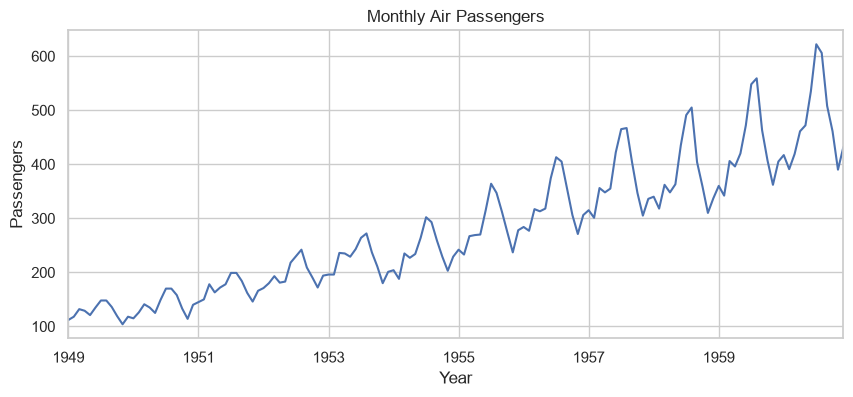

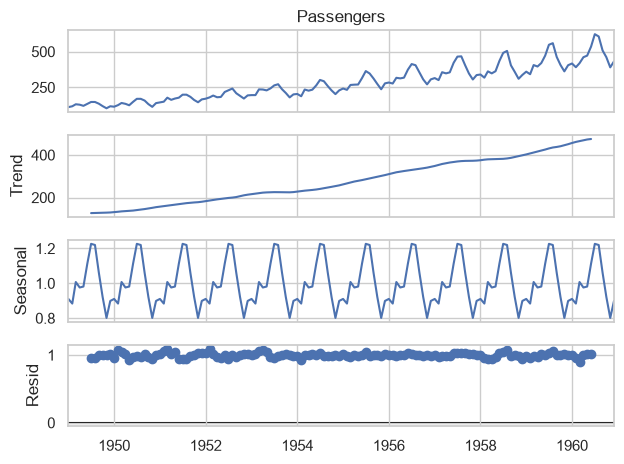

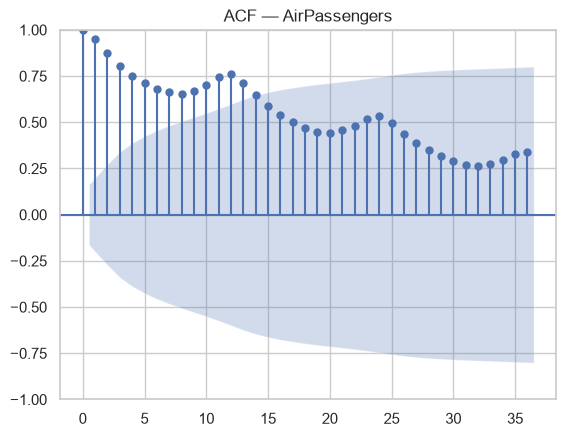

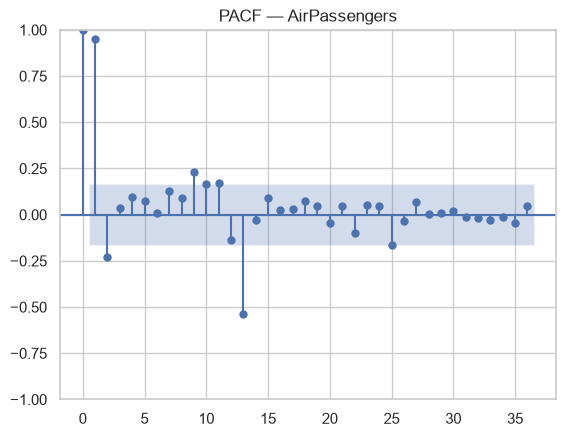

                                    SARIMAX Results                                     
Dep. Variable:                       Passengers   No. Observations:                  144
Model:             ARIMA(1, 1, 1)x(1, 1, 1, 12)   Log Likelihood                -506.149
Date:                          Mon, 19 Oct 2026   AIC                           1022.299
Time:                                  10:05:15   BIC                           1036.675
Sample:                              01-01-1949   HQIC                          1028.140
                                   - 12-01-1960                                         
Covariance Type:                            opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.1272      0.356     -0.358      0.721      -0.825       0.570
ma.L1         -0.2148      0.325     -0.660      0.

,Forecast,Lower_95,Upper_95
1961-01-01,449.330228,426.901304,471.759152
1961-02-01,424.386481,397.539813,451.233149
1961-03-01,459.033584,427.917935,490.149233
1961-04-01,497.865589,463.055647,532.675531
1961-05-01,509.863626,471.709020,548.018232
1961-06-01,568.258775,527.030713,609.486836
1961-07-01,655.811017,611.723149,699.898886
1961-08-01,641.191337,594.418201,687.964472
1961-09-01,546.393477,497.081081,595.705873
1961-10-01,496.801742,445.074585,548.528898


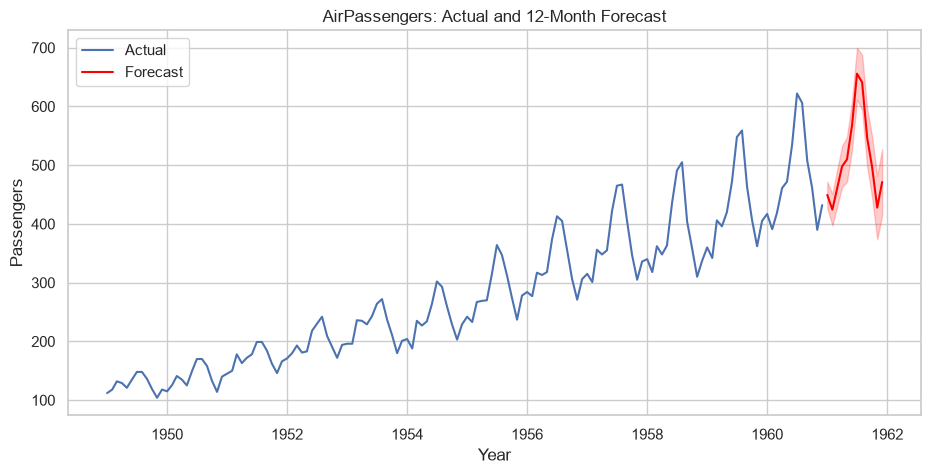

In [ ]:
AIR_URL = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
air = pd.read_csv(AIR_URL, parse_dates=["Month"])
air = air.rename(columns={"Month": "Date", "Passengers": "Passengers"})
air = air.set_index("Date").asfreq("MS")
series = air["Passengers"]

print("First five"); display(air.head())
print("Last five"); display(air.tail())
print("Start:", series.index.min(), "End:", series.index.max())
print("Frequency: monthly (12 observations per year)")
print("Pandas type:", type(series))

series.plot(figsize=(10, 4), title="Monthly Air Passengers")
plt.xlabel("Year"); plt.ylabel("Passengers"); plt.show()

# Decomposition requires at least two complete seasonal cycles
decomp = seasonal_decompose(series, model="multiplicative", period=12)
decomp.plot()
plt.show()

plot_acf(series, lags=36)
plt.title("ACF — AirPassengers"); plt.show()
plot_pacf(series, lags=36, method="ywm")
plt.title("PACF — AirPassengers"); plt.show()

# Seasonal ARIMA: (1,1,1) x (1,1,1,12)
model = ARIMA(series, order=(1, 1, 1), seasonal_order=(1, 1, 1, 12)).fit()
print(model.summary())

forecast_obj = model.get_forecast(steps=12)
forecast_mean = forecast_obj.predicted_mean
conf_int = forecast_obj.conf_int()
display(pd.DataFrame({"Forecast": forecast_mean, "Lower_95": conf_int.iloc[:, 0], "Upper_95": conf_int.iloc[:, 1]}))

plt.figure(figsize=(11, 5))
plt.plot(series.index, series, label="Actual")
plt.plot(forecast_mean.index, forecast_mean, color="red", label="Forecast")
plt.fill_between(forecast_mean.index, conf_int.iloc[:, 0], conf_int.iloc[:, 1], alpha=.2, color="red")
plt.title("AirPassengers: Actual and 12-Month Forecast")
plt.xlabel("Year"); plt.ylabel("Passengers"); plt.legend(); plt.show()

,Statistic,Value
0,Mean,52.630883
1,Median,53.000000
2,Minimum,12.000000
3,Maximum,100.000000
4,Range,88.000000
5,Variance,391.401832
6,Standard Deviation,19.783878
7,IQR,32.000000
8,Skewness,0.014248
9,Kurtosis,-1.003627


,Frequency,Relative_Frequency,Percentage
Sex,,,
female,1328,0.516531,51.653053
male,1243,0.483469,48.346947


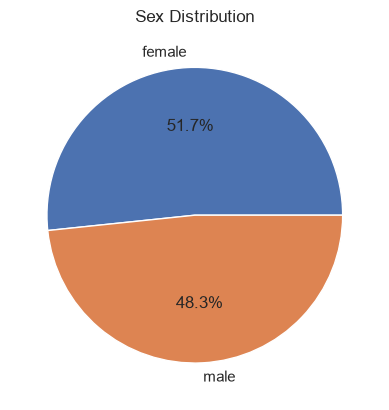

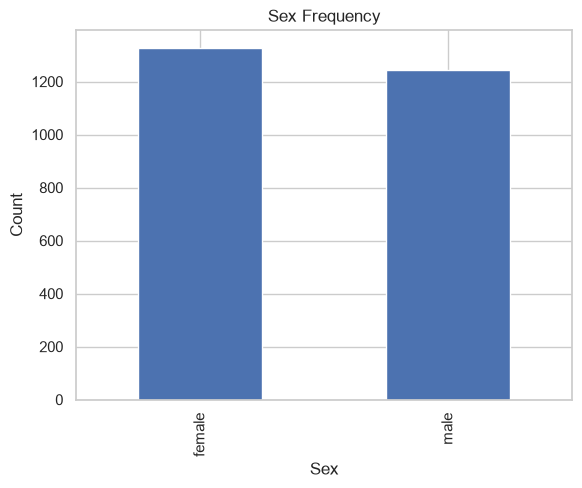

,Frequency
Age,
"[0, 10)",0
"[10, 20)",65
"[20, 30)",356
"[30, 40)",298
"[40, 50)",431
"[50, 60)",439
"[60, 70)",372
"[70, 80)",345
"[80, 90)",239


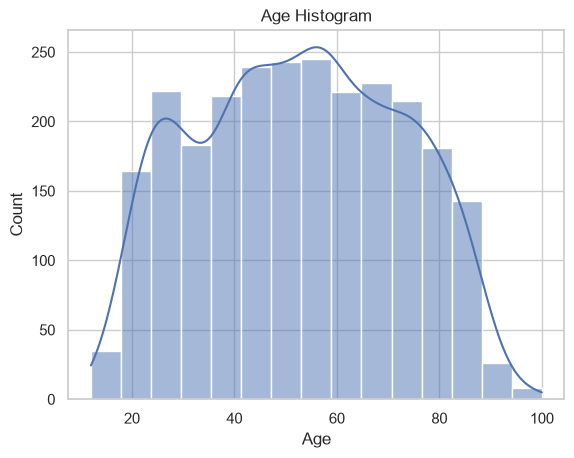

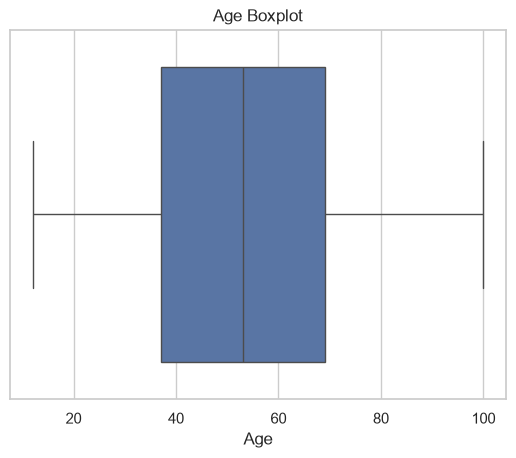

Died,no,yes
Sex,,
female,741,587
male,574,669


Died,no,yes
Sex,,
female,55.798193,44.201807
male,46.178600,53.821400


Died,no,yes
Sex,,
female,56.34981,46.735669
male,43.65019,53.264331


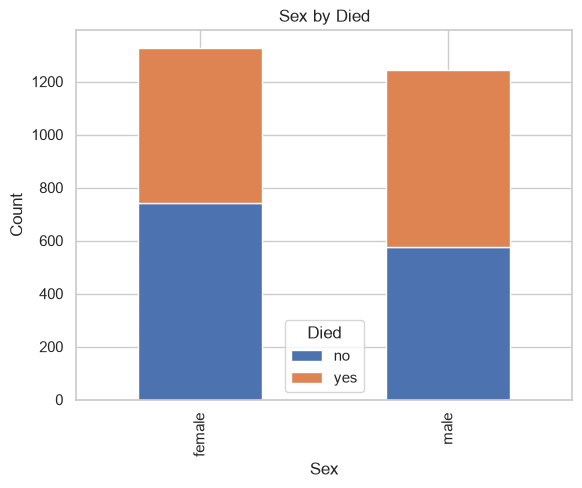

,mean,median,std
Sex,,,
female,51.530120,50.0,20.118878
male,53.806919,55.0,19.358589


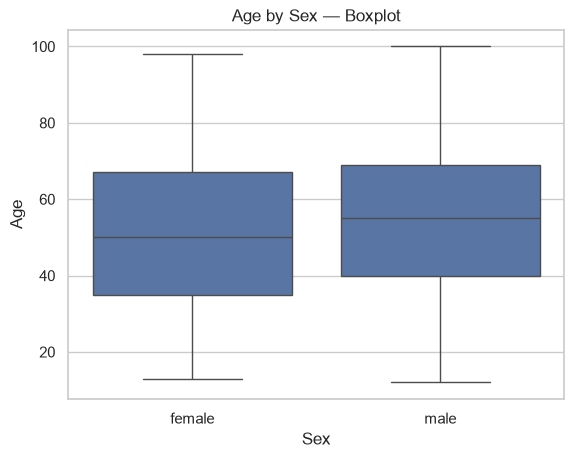

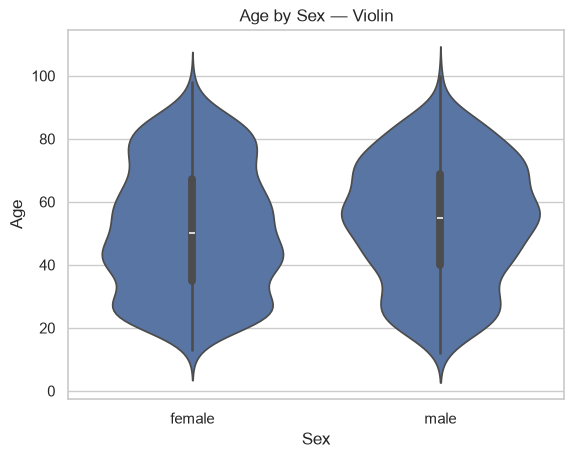

Pearson Age/Month: -0.0283969377702749
Spearman Age/Month: -0.03135477834340074


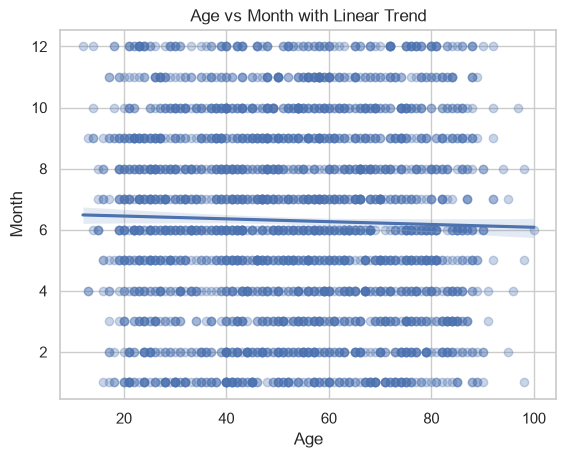

mean        std  count
Sex    Died                             
female no    43.742240  17.928302    741
       yes   61.361158  18.363017    587
male   no    44.602787  17.301224    574
       yes   61.704036  17.457365    669

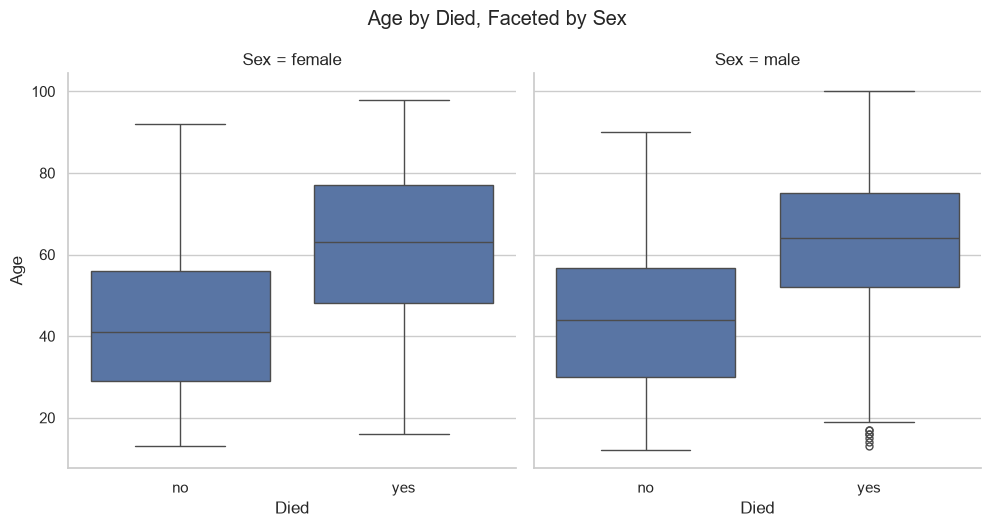

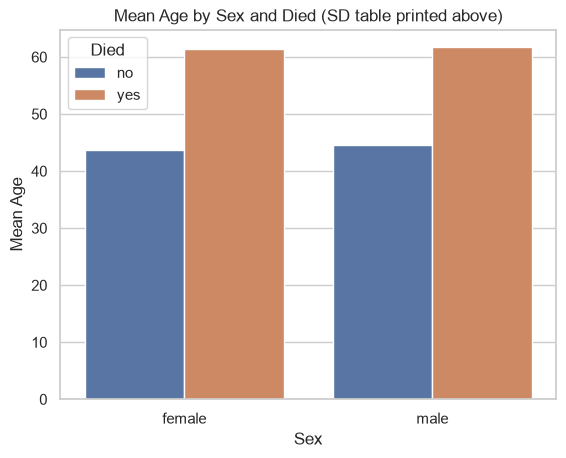

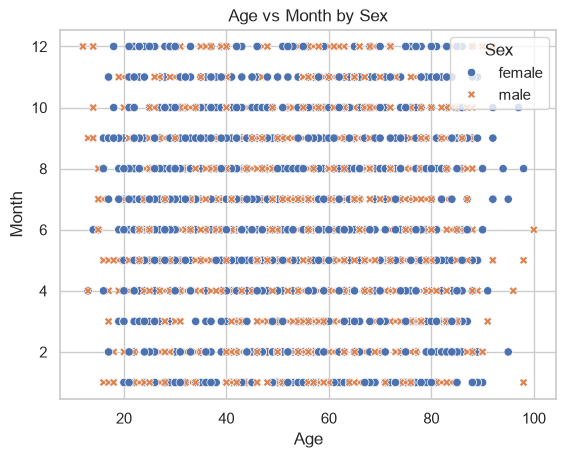

female Pearson correlation: -0.039758258379429354
male Pearson correlation: -0.009703530334725199


,Age,Year,Month
Age,1.000000,-0.017267,-0.028397
Year,-0.017267,1.000000,0.009380
Month,-0.028397,0.009380,1.000000


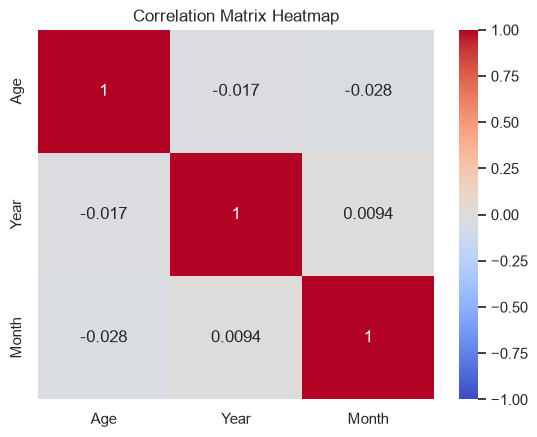

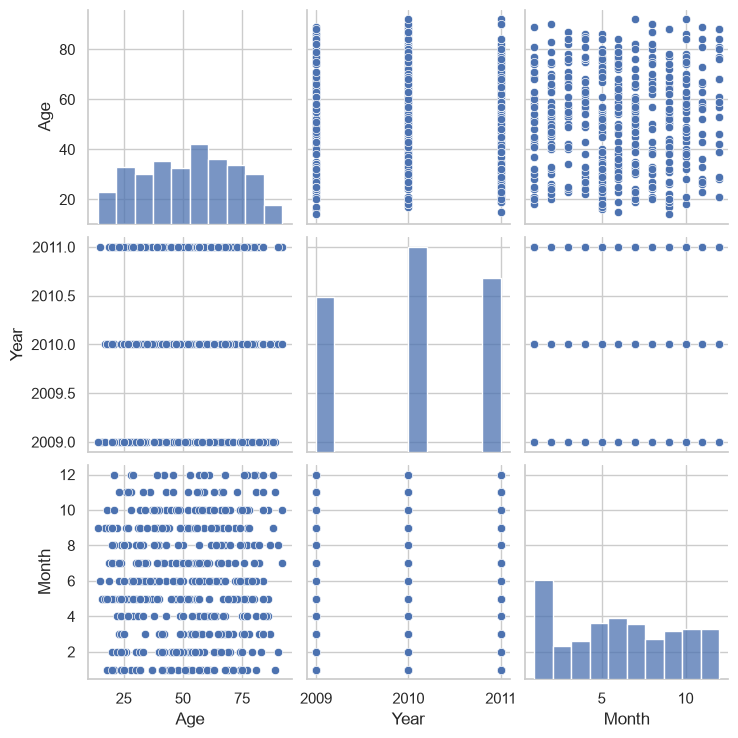

In [ ]:
df7 = data.copy()
x = df7["Age"].dropna()

# 2–3. Summary statistics in one table
stats_table = pd.DataFrame({
    "Statistic": ["Mean", "Median", "Minimum", "Maximum", "Range", "Variance",
                  "Standard Deviation", "IQR", "Skewness", "Kurtosis"],
    "Value": [x.mean(), x.median(), x.min(), x.max(), x.max()-x.min(), x.var(),
              x.std(), x.quantile(.75)-x.quantile(.25), skew(x), kurtosis(x)]
})
display(stats_table)

# 4. Frequency / relative frequency / pie / bar for Sex
freq = df7["Sex"].value_counts()
rel = df7["Sex"].value_counts(normalize=True)
display(pd.DataFrame({"Frequency": freq, "Relative_Frequency": rel, "Percentage": rel*100}))
freq.plot(kind="pie", autopct="%1.1f%%", title="Sex Distribution", ylabel="")
plt.show()
freq.plot(kind="bar", title="Sex Frequency"); plt.ylabel("Count"); plt.show()

# 5. Numerical bins, histogram, boxplot
age_bins = pd.cut(df7["Age"], bins=range(0, 111, 10), right=False)
display(age_bins.value_counts().sort_index().to_frame("Frequency"))
sns.histplot(df7["Age"], bins=15, kde=True)
plt.title("Age Histogram"); plt.show()
sns.boxplot(x=df7["Age"]); plt.title("Age Boxplot"); plt.show()

# 6–7. Contingency table and row/column percentages
ct = pd.crosstab(df7["Sex"], df7["Died"])
display(ct)
display(ct.div(ct.sum(axis=1), axis=0) * 100)  # row percentages
display(ct.div(ct.sum(axis=0), axis=1) * 100)  # column percentages
ct.plot(kind="bar", stacked=True, title="Sex by Died")
plt.ylabel("Count"); plt.show()

# 8. Grouped mean, median, SD
display(df7.groupby("Sex")["Age"].agg(["mean", "median", "std"]))

# 9. Side-by-side box and violin
sns.boxplot(data=df7, x="Sex", y="Age"); plt.title("Age by Sex — Boxplot"); plt.show()
sns.violinplot(data=df7, x="Sex", y="Age"); plt.title("Age by Sex — Violin"); plt.show()

# 10. Pearson and Spearman correlation; scatter with fitted line
print("Pearson Age/Month:", df7["Age"].corr(df7["Month"], method="pearson"))
print("Spearman Age/Month:", df7["Age"].corr(df7["Month"], method="spearman"))
sns.regplot(data=df7, x="Age", y="Month", scatter_kws={"alpha": .3})
plt.title("Age vs Month with Linear Trend"); plt.show()

# 11. Two categories + one numeric: summaries and faceted box plot
display(df7.groupby(["Sex", "Died"], observed=False)["Age"].agg(["mean", "std", "count"]))
g = sns.catplot(data=df7, x="Died", y="Age", col="Sex", kind="box")
g.fig.suptitle("Age by Died, Faceted by Sex", y=1.05); plt.show()

# Grouped mean with standard deviation error bars
summary = df7.groupby(["Sex", "Died"], observed=False)["Age"].agg(["mean", "std"]).reset_index()
sns.barplot(data=summary, x="Sex", y="mean", hue="Died")
plt.title("Mean Age by Sex and Died (SD table printed above)")
plt.ylabel("Mean Age"); plt.show()

# 12. One category + two numeric, correlations by category
sns.scatterplot(data=df7, x="Age", y="Month", hue="Sex", style="Sex")
plt.title("Age vs Month by Sex"); plt.show()
for group, part in df7.groupby("Sex"):
    print(group, "Pearson correlation:", part["Age"].corr(part["Month"]))

# 13. Correlation matrix / heatmap
corr = df7[["Age", "Year", "Month"]].corr()
display(corr)
sns.heatmap(corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Matrix Heatmap"); plt.show()

# 14. Pair plot
sns.pairplot(df7[["Age", "Year", "Month"]].sample(min(500, len(df7)), random_state=RANDOM_STATE))
plt.show()

Shape: (2571, 12)


,rownames,Person_ID,Hospitalised,Died,Urban,Year,Month,Sex,Age,Education,Occupation,method
0,1,1,yes,no,no,2010,12,female,39,Secondary,household,Other poison
1,2,2,no,yes,no,2009,3,male,83,primary,farming,Hanging
2,3,3,no,yes,no,2010,2,male,60,primary,farming,Hanging
3,4,4,no,yes,no,2011,1,male,73,primary,farming,Hanging
4,5,5,yes,no,no,2009,8,male,51,Secondary,farming,Pesticide


Missing values by column:
rownames        0
Person_ID       0
Hospitalised    0
Died            0
Urban           0
Year            0
Month           0
Sex             0
Age             0
Education       0
Occupation      0
method          0
dtype: int64
Died distribution:
Died
no     1315
yes    1256
Name: count, dtype: int64
K=2 inertia / WCSS: 5819.668128595531
Cluster centers (standardized scale):
[[ 0.32657183 -0.79588568 -0.01862585]
 [-0.32479836  0.79156357  0.0185247 ]]
Cluster sizes:
0    1284
1    1287
Name: count, dtype: int64


,K,WCSS
0,1,7713.000000
1,2,5819.668129
2,3,4551.427118
3,4,3646.542989
4,5,3082.049289
5,6,2614.018221
6,7,2315.871266
7,8,2076.355454
8,9,1873.602657
9,10,1696.952470


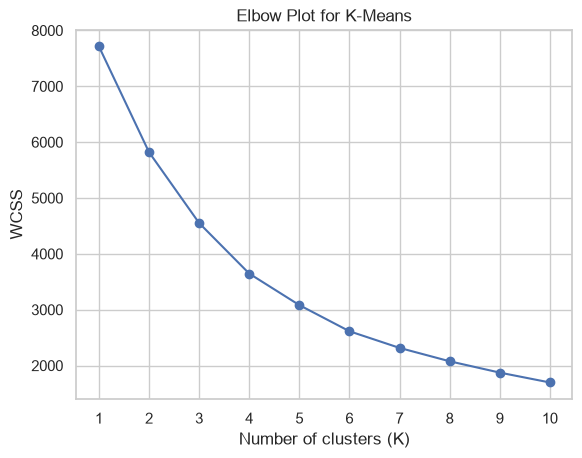

Chosen K: 3
Centers: [[ 0.15951179  0.51134175 -0.85387822]
 [-0.15416363  0.57439215  0.815258  ]
 [-0.00273578 -1.32132315  0.02691695]]
Cluster sizes: 0    900
1    922
2    749
Name: count, dtype: int64


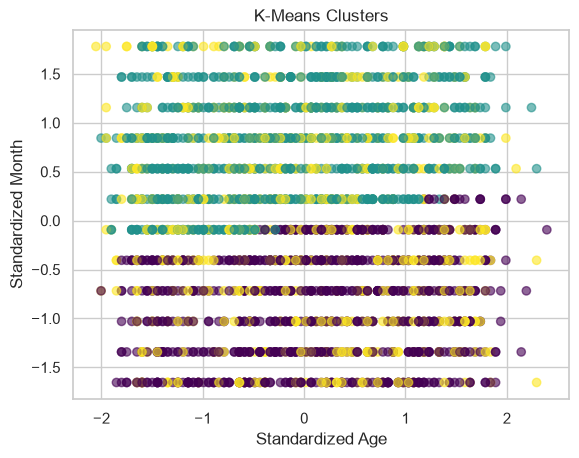

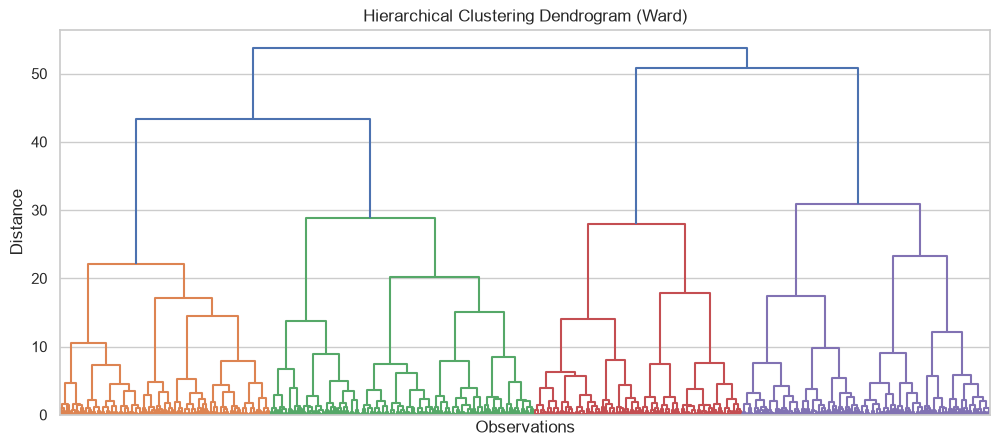

First cluster assignments: [3 1 1 2 1 3 1 3 1 2]
Samples per hierarchical cluster:
1    1311
2     574
3     686
Name: count, dtype: int64


In [ ]:
df8 = data.copy()
print("Shape:", df8.shape)
display(df8.head())
print("Missing values by column:")
print(df8.isna().sum())
print("Died distribution:")
print(df8["Died"].value_counts(dropna=False))

cluster_features = df8[["Age", "Year", "Month"]].dropna()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(cluster_features)

# K-Means with k=2
kmeans2 = KMeans(n_clusters=2, n_init=25, random_state=RANDOM_STATE)
labels2 = kmeans2.fit_predict(X_scaled)
print("K=2 inertia / WCSS:", kmeans2.inertia_)
print("Cluster centers (standardized scale):")
print(kmeans2.cluster_centers_)
print("Cluster sizes:")
print(pd.Series(labels2).value_counts().sort_index())

# WCSS for K=1..10 and elbow plot
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, n_init=25, random_state=RANDOM_STATE)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

display(pd.DataFrame({"K": range(1, 11), "WCSS": wcss}))
plt.plot(range(1, 11), wcss, marker="o")
plt.xlabel("Number of clusters (K)"); plt.ylabel("WCSS")
plt.title("Elbow Plot for K-Means"); plt.xticks(range(1, 11)); plt.show()

# Set this after inspecting the elbow plot
optimal_k = 3
final_kmeans = KMeans(n_clusters=optimal_k, n_init=25, random_state=RANDOM_STATE)
final_labels = final_kmeans.fit_predict(X_scaled)
print("Chosen K:", optimal_k)
print("Centers:", final_kmeans.cluster_centers_)
print("Cluster sizes:", pd.Series(final_labels).value_counts().sort_index())

plt.scatter(X_scaled[:, 0], X_scaled[:, 2], c=final_labels, cmap="viridis", alpha=.6)
plt.xlabel("Standardized Age"); plt.ylabel("Standardized Month")
plt.title("K-Means Clusters"); plt.show()

# Hierarchical clustering: Euclidean distance + Ward linkage
distances = pdist(X_scaled, metric="euclidean")
Z = linkage(distances, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Hierarchical Clustering Dendrogram (Ward)")
plt.xlabel("Observations"); plt.ylabel("Distance"); plt.show()

hier_labels = fcluster(Z, t=3, criterion="maxclust")
print("First cluster assignments:", hier_labels[:10])
print("Samples per hierarchical cluster:")
print(pd.Series(hier_labels).value_counts().sort_index())

Rows and columns: (2571, 12)
Explained variance (%): [34.6  33.06 32.34]
Cumulative variance (%): [ 34.6   67.66 100.  ]


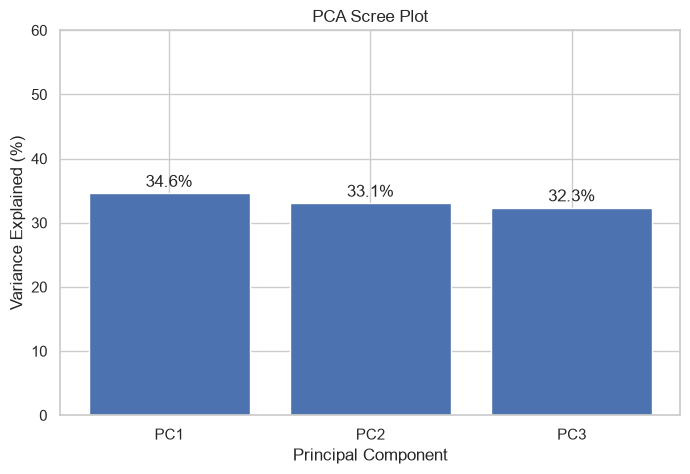

,PC1,PC2
0,-1.503668,-1.010354
1,2.226431,-0.418833
2,1.082234,0.653100
3,1.135315,1.991164
4,0.218439,-1.409500
5,0.018027,-1.780645


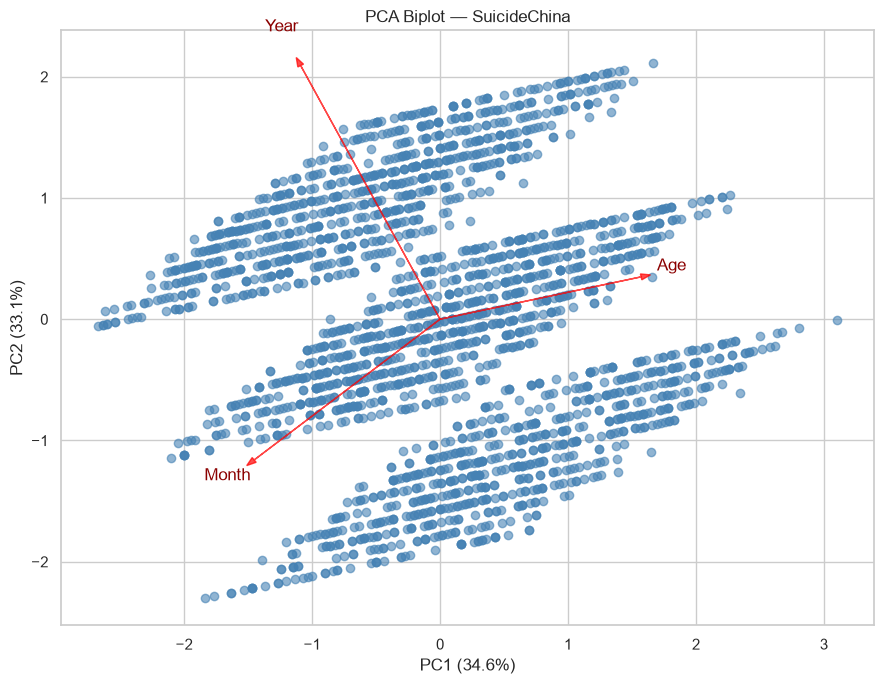

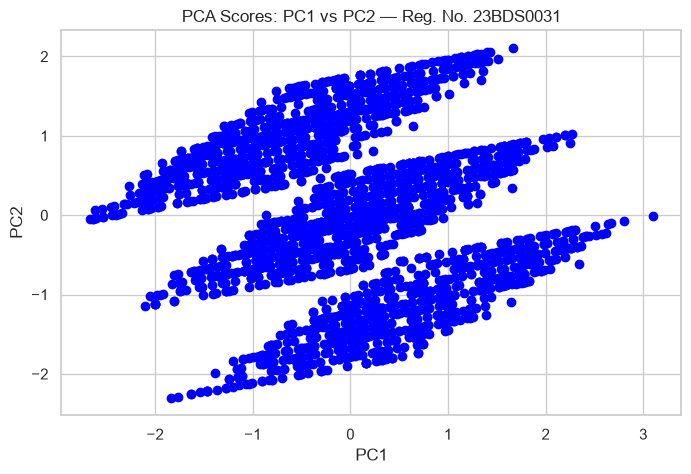

In [17]:
df9 = data.copy()
print("Rows and columns:", df9.shape)

# Extract numerical columns, excluding identifiers
exclude = [c for c in ["Person_ID", "rownames"] if c in df9.columns]
numeric_df = df9.select_dtypes(include=np.number).drop(columns=exclude, errors="ignore")

# Clean missing values using column medians
numeric_df = numeric_df.replace([np.inf, -np.inf], np.nan)
numeric_df = numeric_df.fillna(numeric_df.median())

# Standardize
scaler_pca = StandardScaler()
data_scaled = scaler_pca.fit_transform(numeric_df)

# PCA
pca = PCA()
pca.fit(data_scaled)
explained = pca.explained_variance_ratio_ * 100
cumulative = np.cumsum(explained)
print("Explained variance (%):", np.round(explained, 2))
print("Cumulative variance (%):", np.round(cumulative, 2))

# Scree plot with percentage labels and y-axis 0–60 as requested
plt.figure(figsize=(8, 5))
components = np.arange(1, len(explained) + 1)
plt.bar(components, explained)
for i, value in enumerate(explained):
    plt.text(i + 1, value + 1, f"{value:.1f}%", ha="center")
plt.ylim(0, 60)
plt.xticks(components, [f"PC{i}" for i in components])
plt.xlabel("Principal Component"); plt.ylabel("Variance Explained (%)")
plt.title("PCA Scree Plot")
plt.show()

# PCA scores
scores_array = pca.transform(data_scaled)
pca_scores = pd.DataFrame(
    scores_array[:, :min(2, scores_array.shape[1])],
    columns=[f"PC{i}" for i in range(1, min(2, scores_array.shape[1]) + 1)],
    index=numeric_df.index
)
display(pca_scores.head(6))

# PCA biplot for PC1 and PC2 (works when at least two numeric variables exist)
if pca.components_.shape[0] >= 2:
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.scatter(scores_array[:, 0], scores_array[:, 1], alpha=.6, color="steelblue")
    loadings = pca.components_.T[:, :2]
    scale_arrow = 2.5
    for i, name in enumerate(numeric_df.columns):
        ax.arrow(0, 0, loadings[i, 0] * scale_arrow, loadings[i, 1] * scale_arrow,
                 color="red", alpha=.7, head_width=.05, length_includes_head=True)
        ax.text(loadings[i, 0] * scale_arrow * 1.1,
                loadings[i, 1] * scale_arrow * 1.1,
                name, color="darkred", ha="center")
    ax.set_xlabel(f"PC1 ({explained[0]:.1f}%)")
    ax.set_ylabel(f"PC2 ({explained[1]:.1f}%)")
    ax.set_title("PCA Biplot — SuicideChina")
    plt.tight_layout()
    plt.show()

# PC1 vs PC2 with blue circular points and registration number in title
REGISTRATION_NUMBER = "23BDS0031"  # replace with yours
if scores_array.shape[1] >= 2:
    plt.figure(figsize=(8, 5))
    plt.scatter(scores_array[:, 0], scores_array[:, 1], color="blue", marker="o")
    plt.xlabel("PC1"); plt.ylabel("PC2")
    plt.title(f"PCA Scores: PC1 vs PC2 — Reg. No. {REGISTRATION_NUMBER}")
    plt.show()